**Question 3: Sampling Data**

(a) First a sampling interval of dt = 1 second was used to sample function $g(t) = \cos(2 \pi ft)$ for frequency values of $f = 0,0.25,0.5,0.75,1.0$ Hz. Samples were generated for a total of 10 seconds for every frequency value. To judge whether the coarse sampling captures the original dataset faithfully, we can define this as whether the sampled data correctly identifies the ground truth frequency (and perhaps amplitude so it can recreate the waveform). 

For each frequency tested: 

f = 0 Hz: since this is a constant function, the coarse sampling captures it faithfully

f = 0.25 Hz: The frequency and amplitude can both be recreated, it captures it faithfully

f = 0.5 Hz: This was also captured faithfully, but borderline so, the extremas are recreated, but the zeros between are implied

f = 0.75 Hz: This was not captured faithfully, the sampled frequency estimated was 3 times smaller

f = 1.0 Hz: The sampling frequency exactly coincides with the period of the waveform, and looks like it generates a constant function with no period, this does not capture it faithfully. 

(b) For each sampling frequency we can average the result, and find it's amplitude by averaging the maximum and minimum value. Then the sampled frequency is found by finding the first repetition of the first data point in the sampled array. Because of computer precision error, this is done by comparing the absolute difference between each data point and the first at t = 0, then taking the value which falls within an error tolerance of 10^-6. Additionally a slope check is used to guarantee that the repeat is the same sign as the original and not an intermediate point with a similar value (recommended by AI). The results showed that the maximum frequency correctly sampled with the sampling rate of dt = 1s was f = 0.5 Hz. When the sampling gets coarser than this value, the signal is oscillating too fast which results in a sampled frequency much slower than the ground truth. 

(c) Now around an estimated $f_{max} = 0.5$ Hz. New samples were generated with sampling frequencies $f = f_{max} − 0.1$, and $f_{max} + 0.1$. i.e. $f = 0.4$ Hz and 0.6 Hz. Part b) was repeated (also plotted them too), the estimated frequencies were BOTH 0.2 Hz. Although the first case falls under the assumed maximum where we can still faithfully reconstruct the frequency, it still doesn't give the correct value. This however is not because the sample frequency is too slow in comparison to the oscillation, like the other case (aliasing), but it's just due to the placement of the sample points upon observation.

AI: Used to improve period finding - slope detection

Collaborators: Valerie MacIsaac

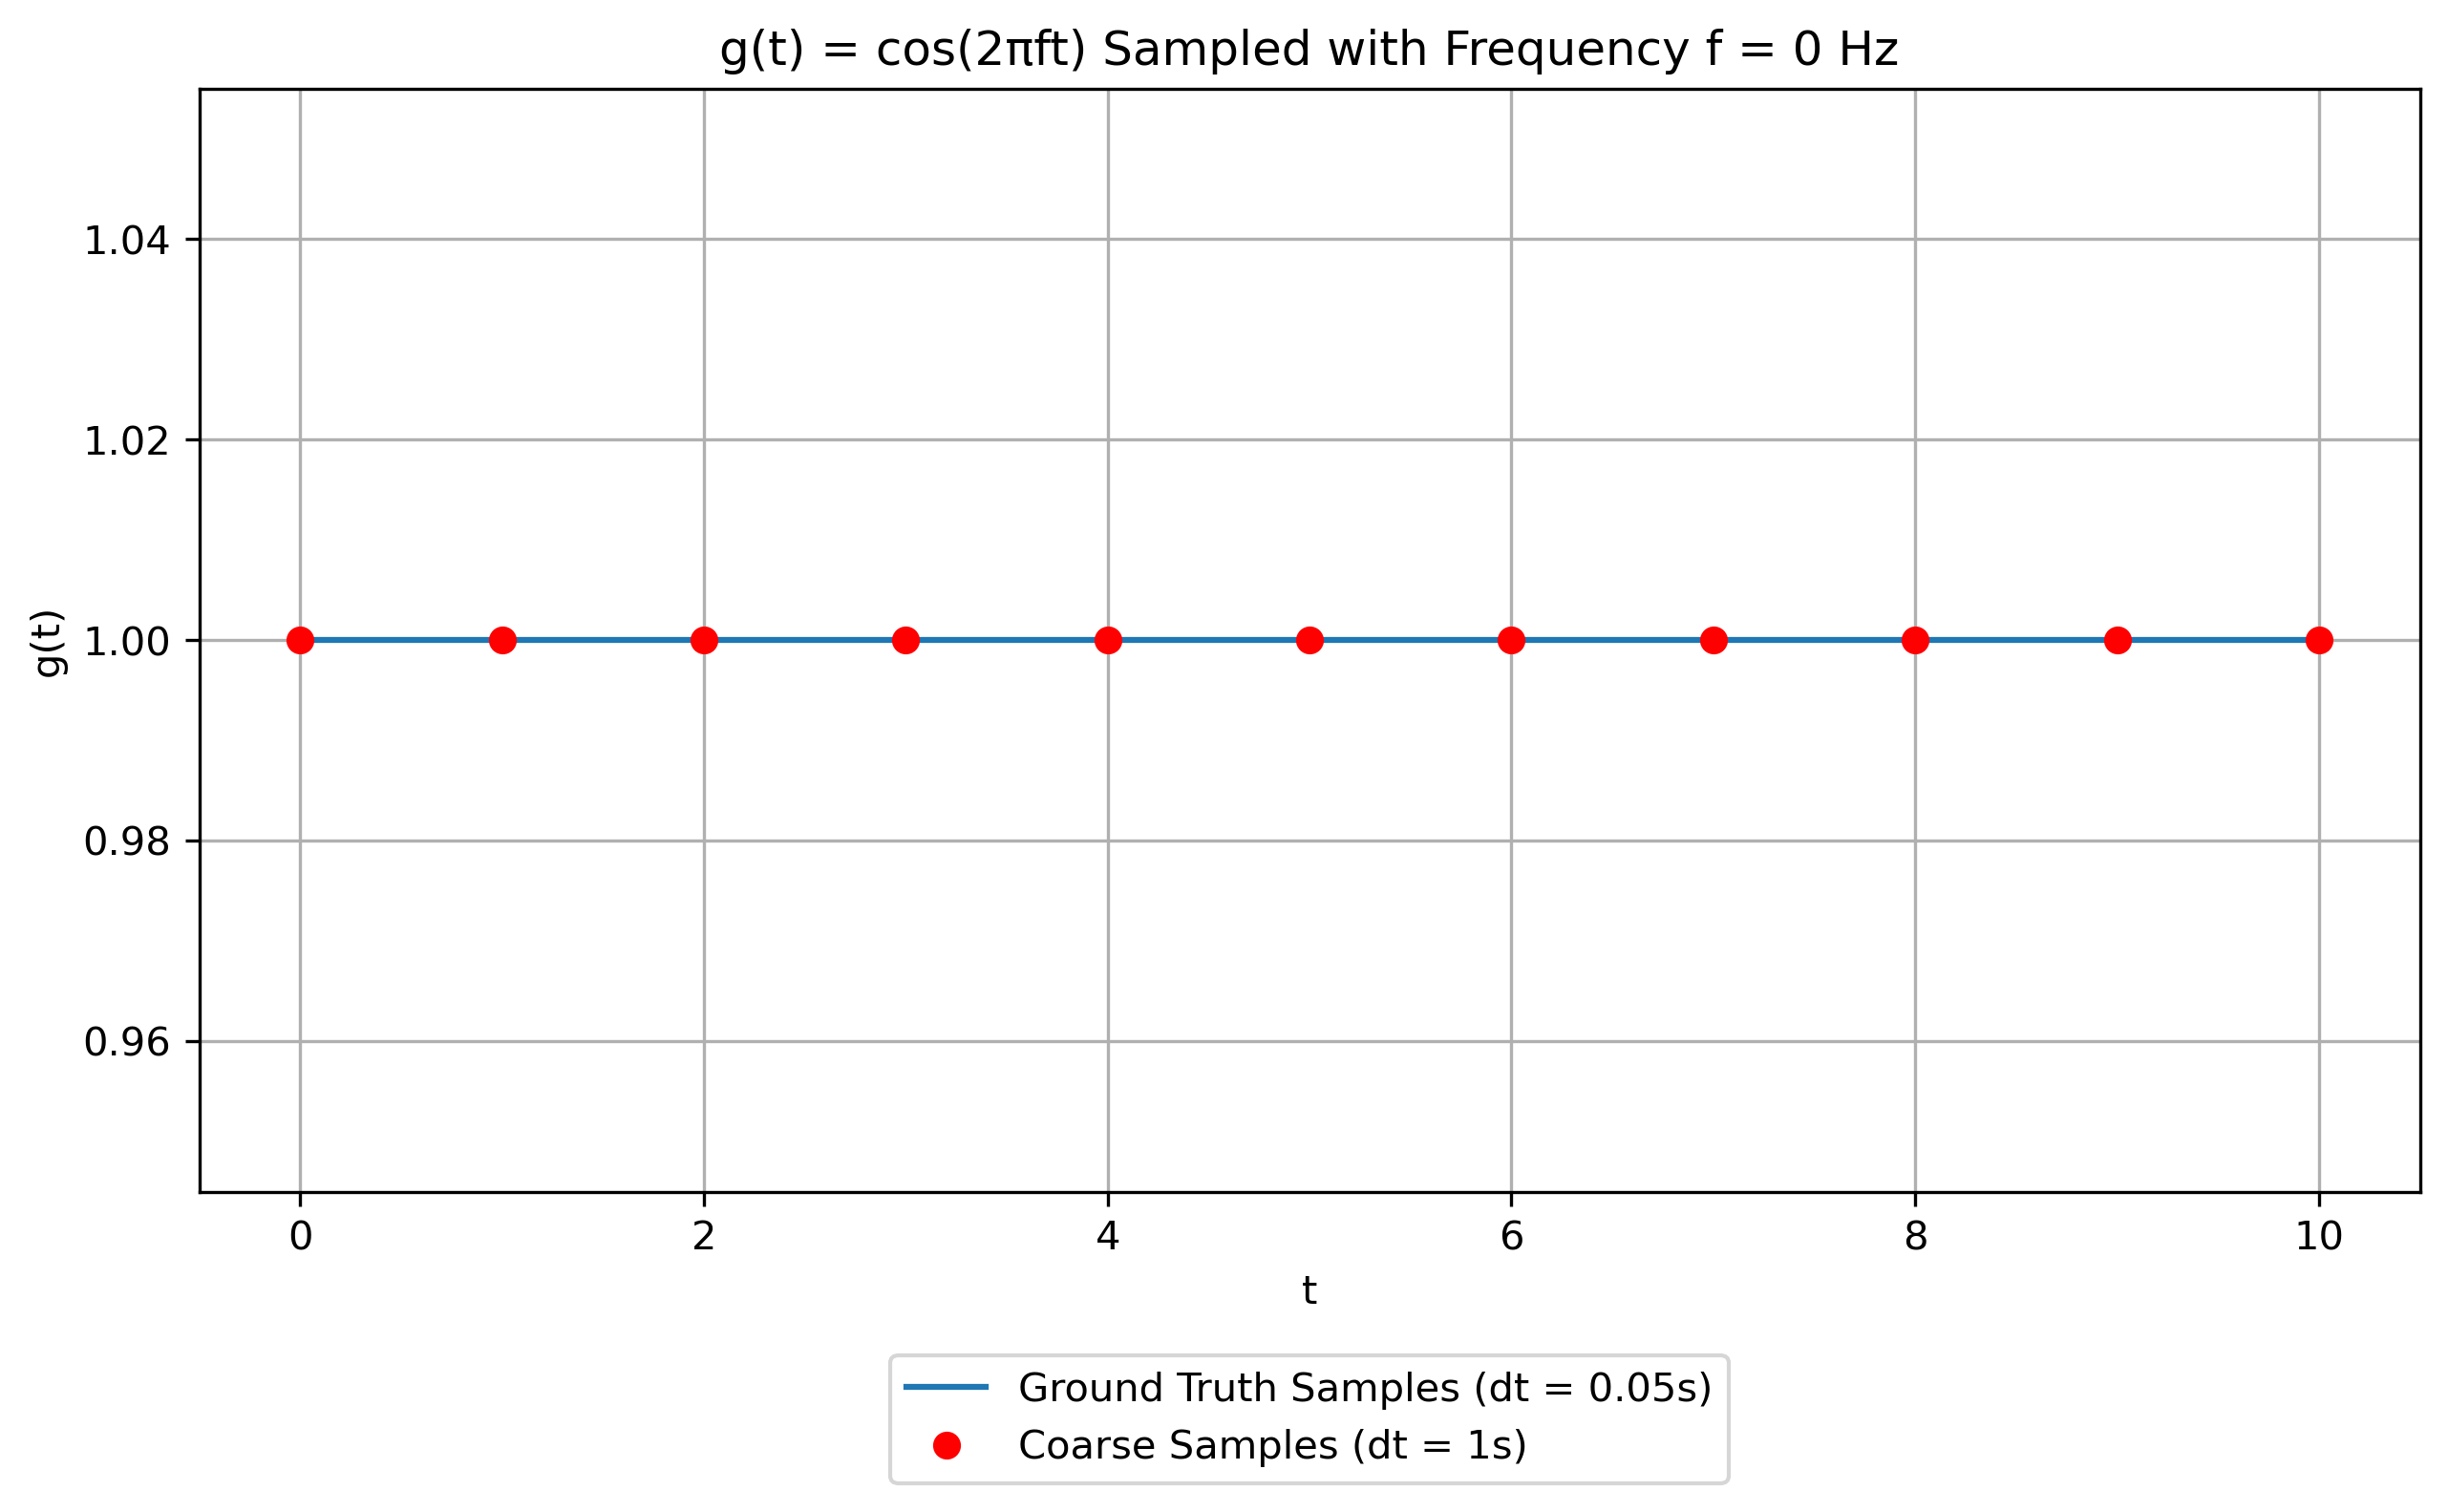

Average is 1.0 for ground truth f = 0
No periodicity detected for ground f = 0
Amplitude of sampled data for ground truth f = 0 is 0.0


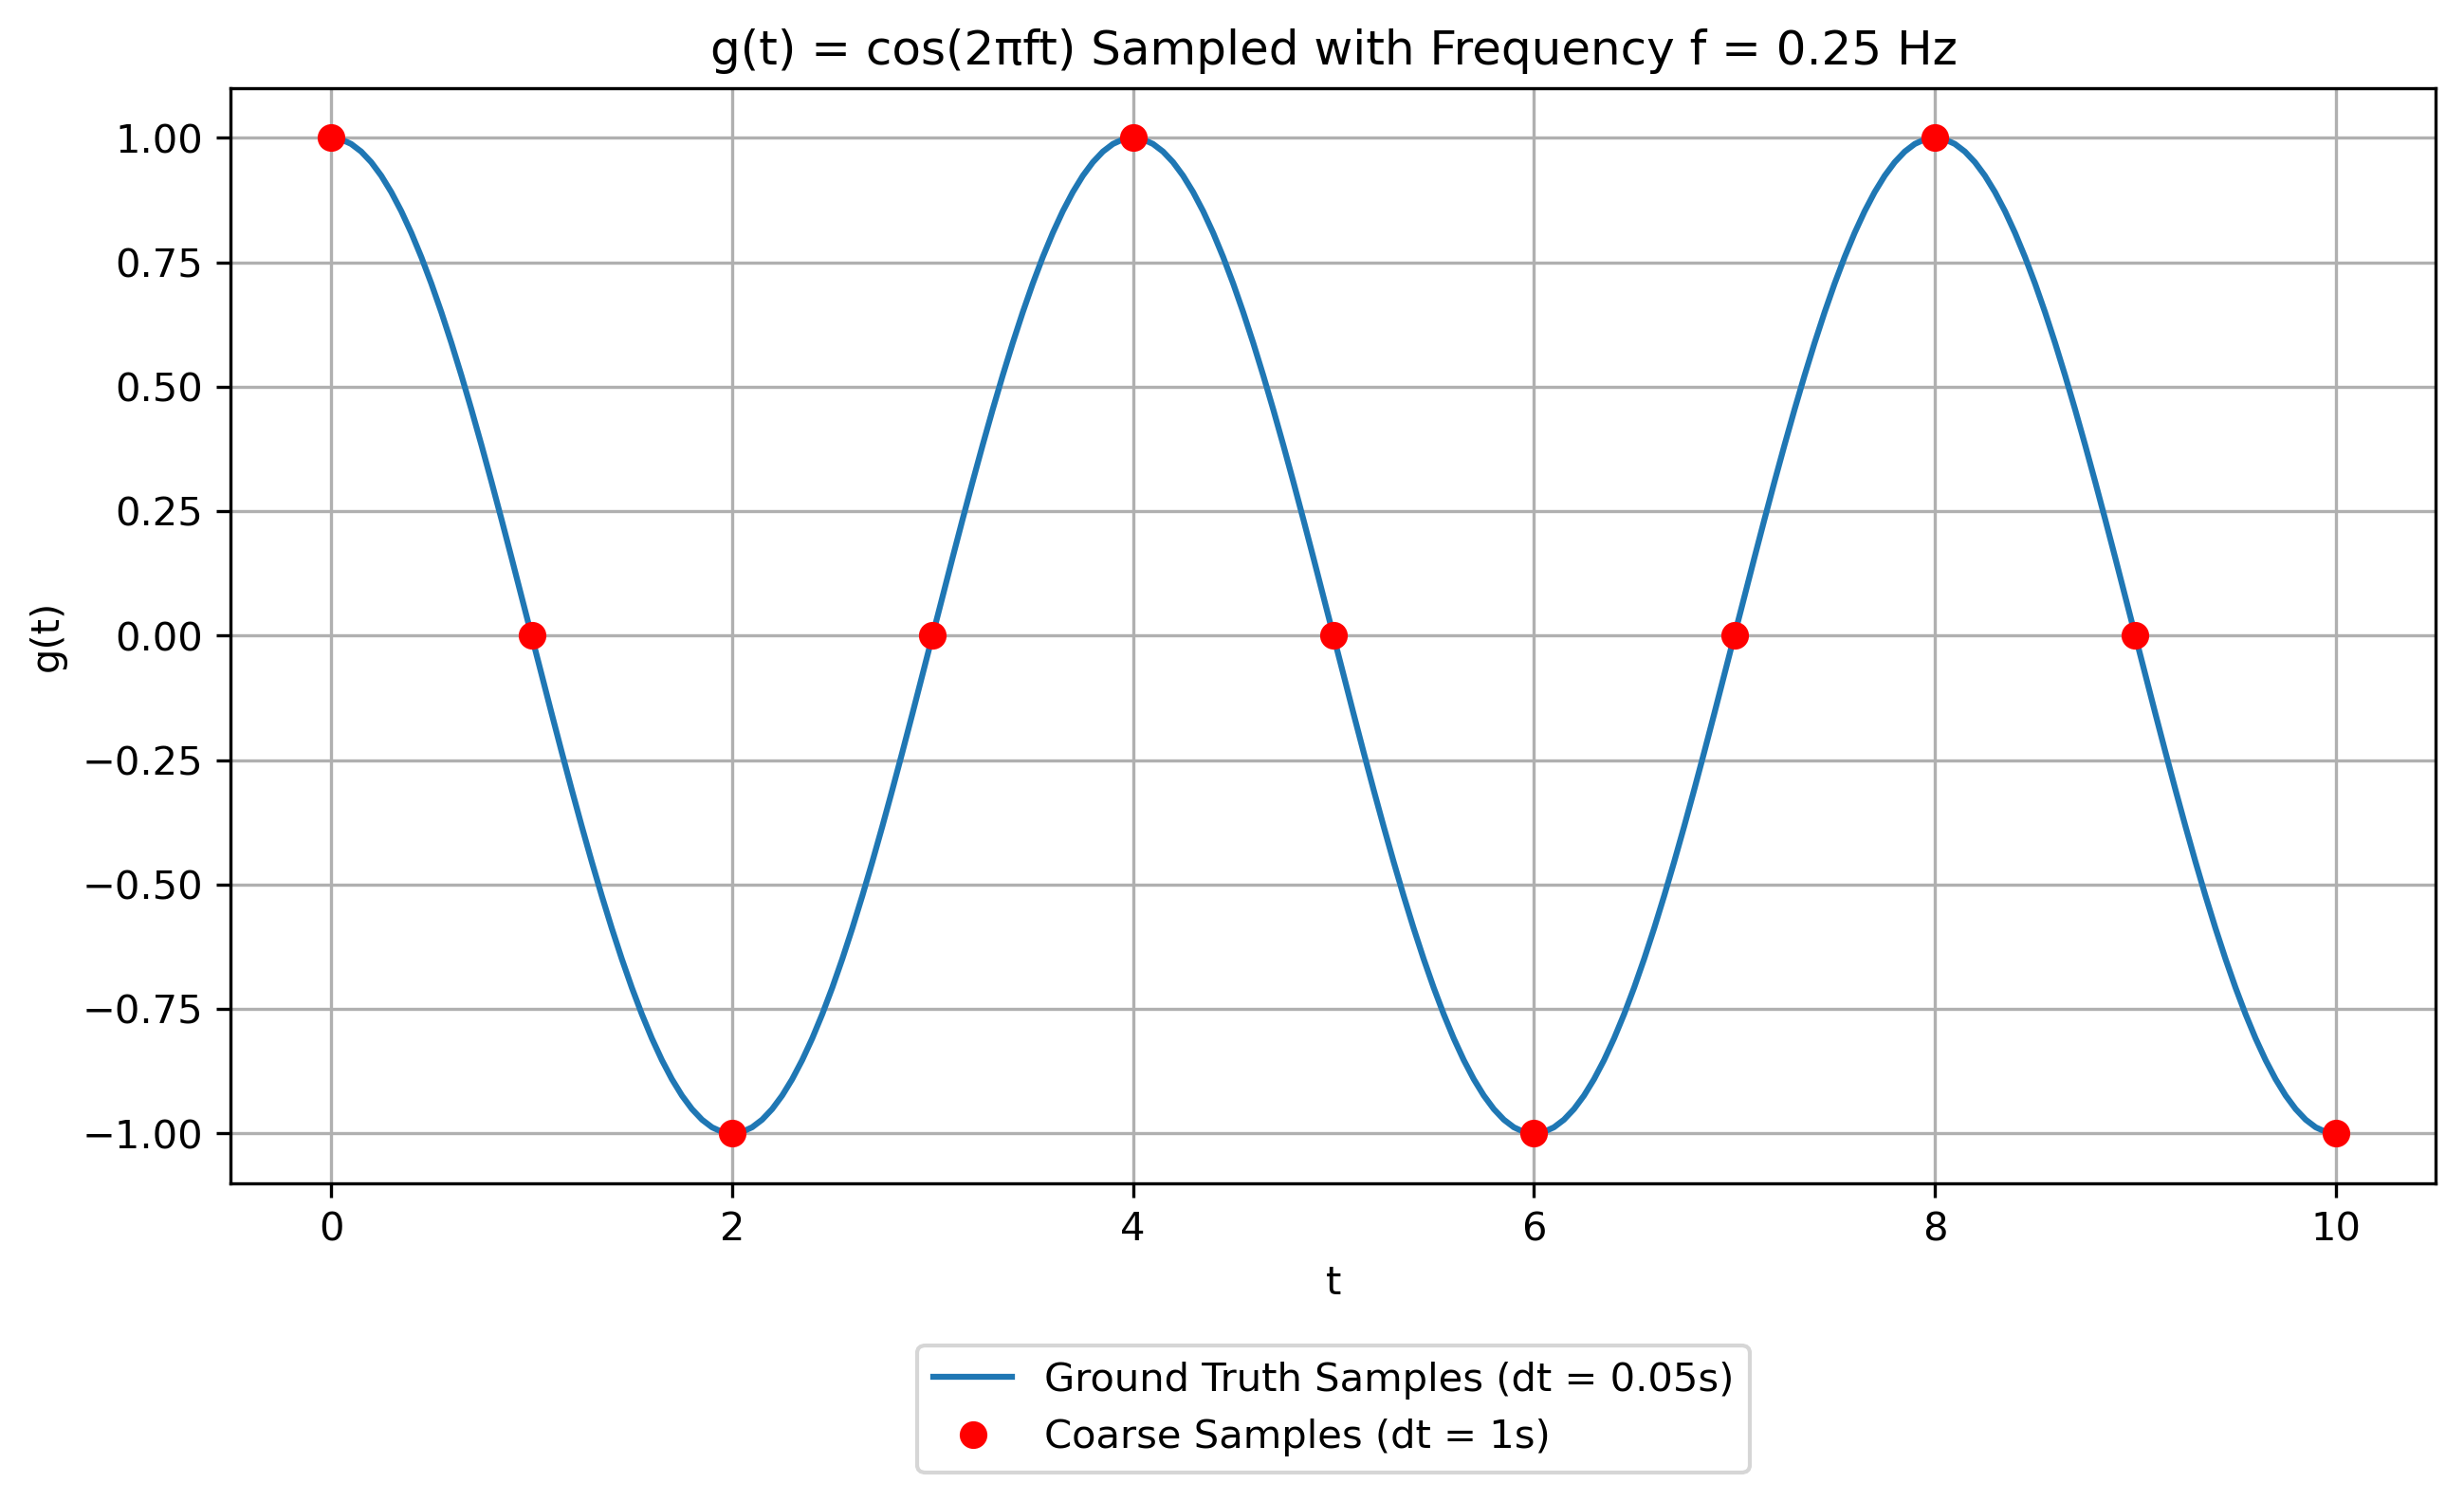

Average is 0.0 for ground truth f = 0.25
Ground truth frequency = 0.25, Sampled/Apparent frequency = 0.25
Amplitude of sampled data for ground truth f = 0.25 is 1.0


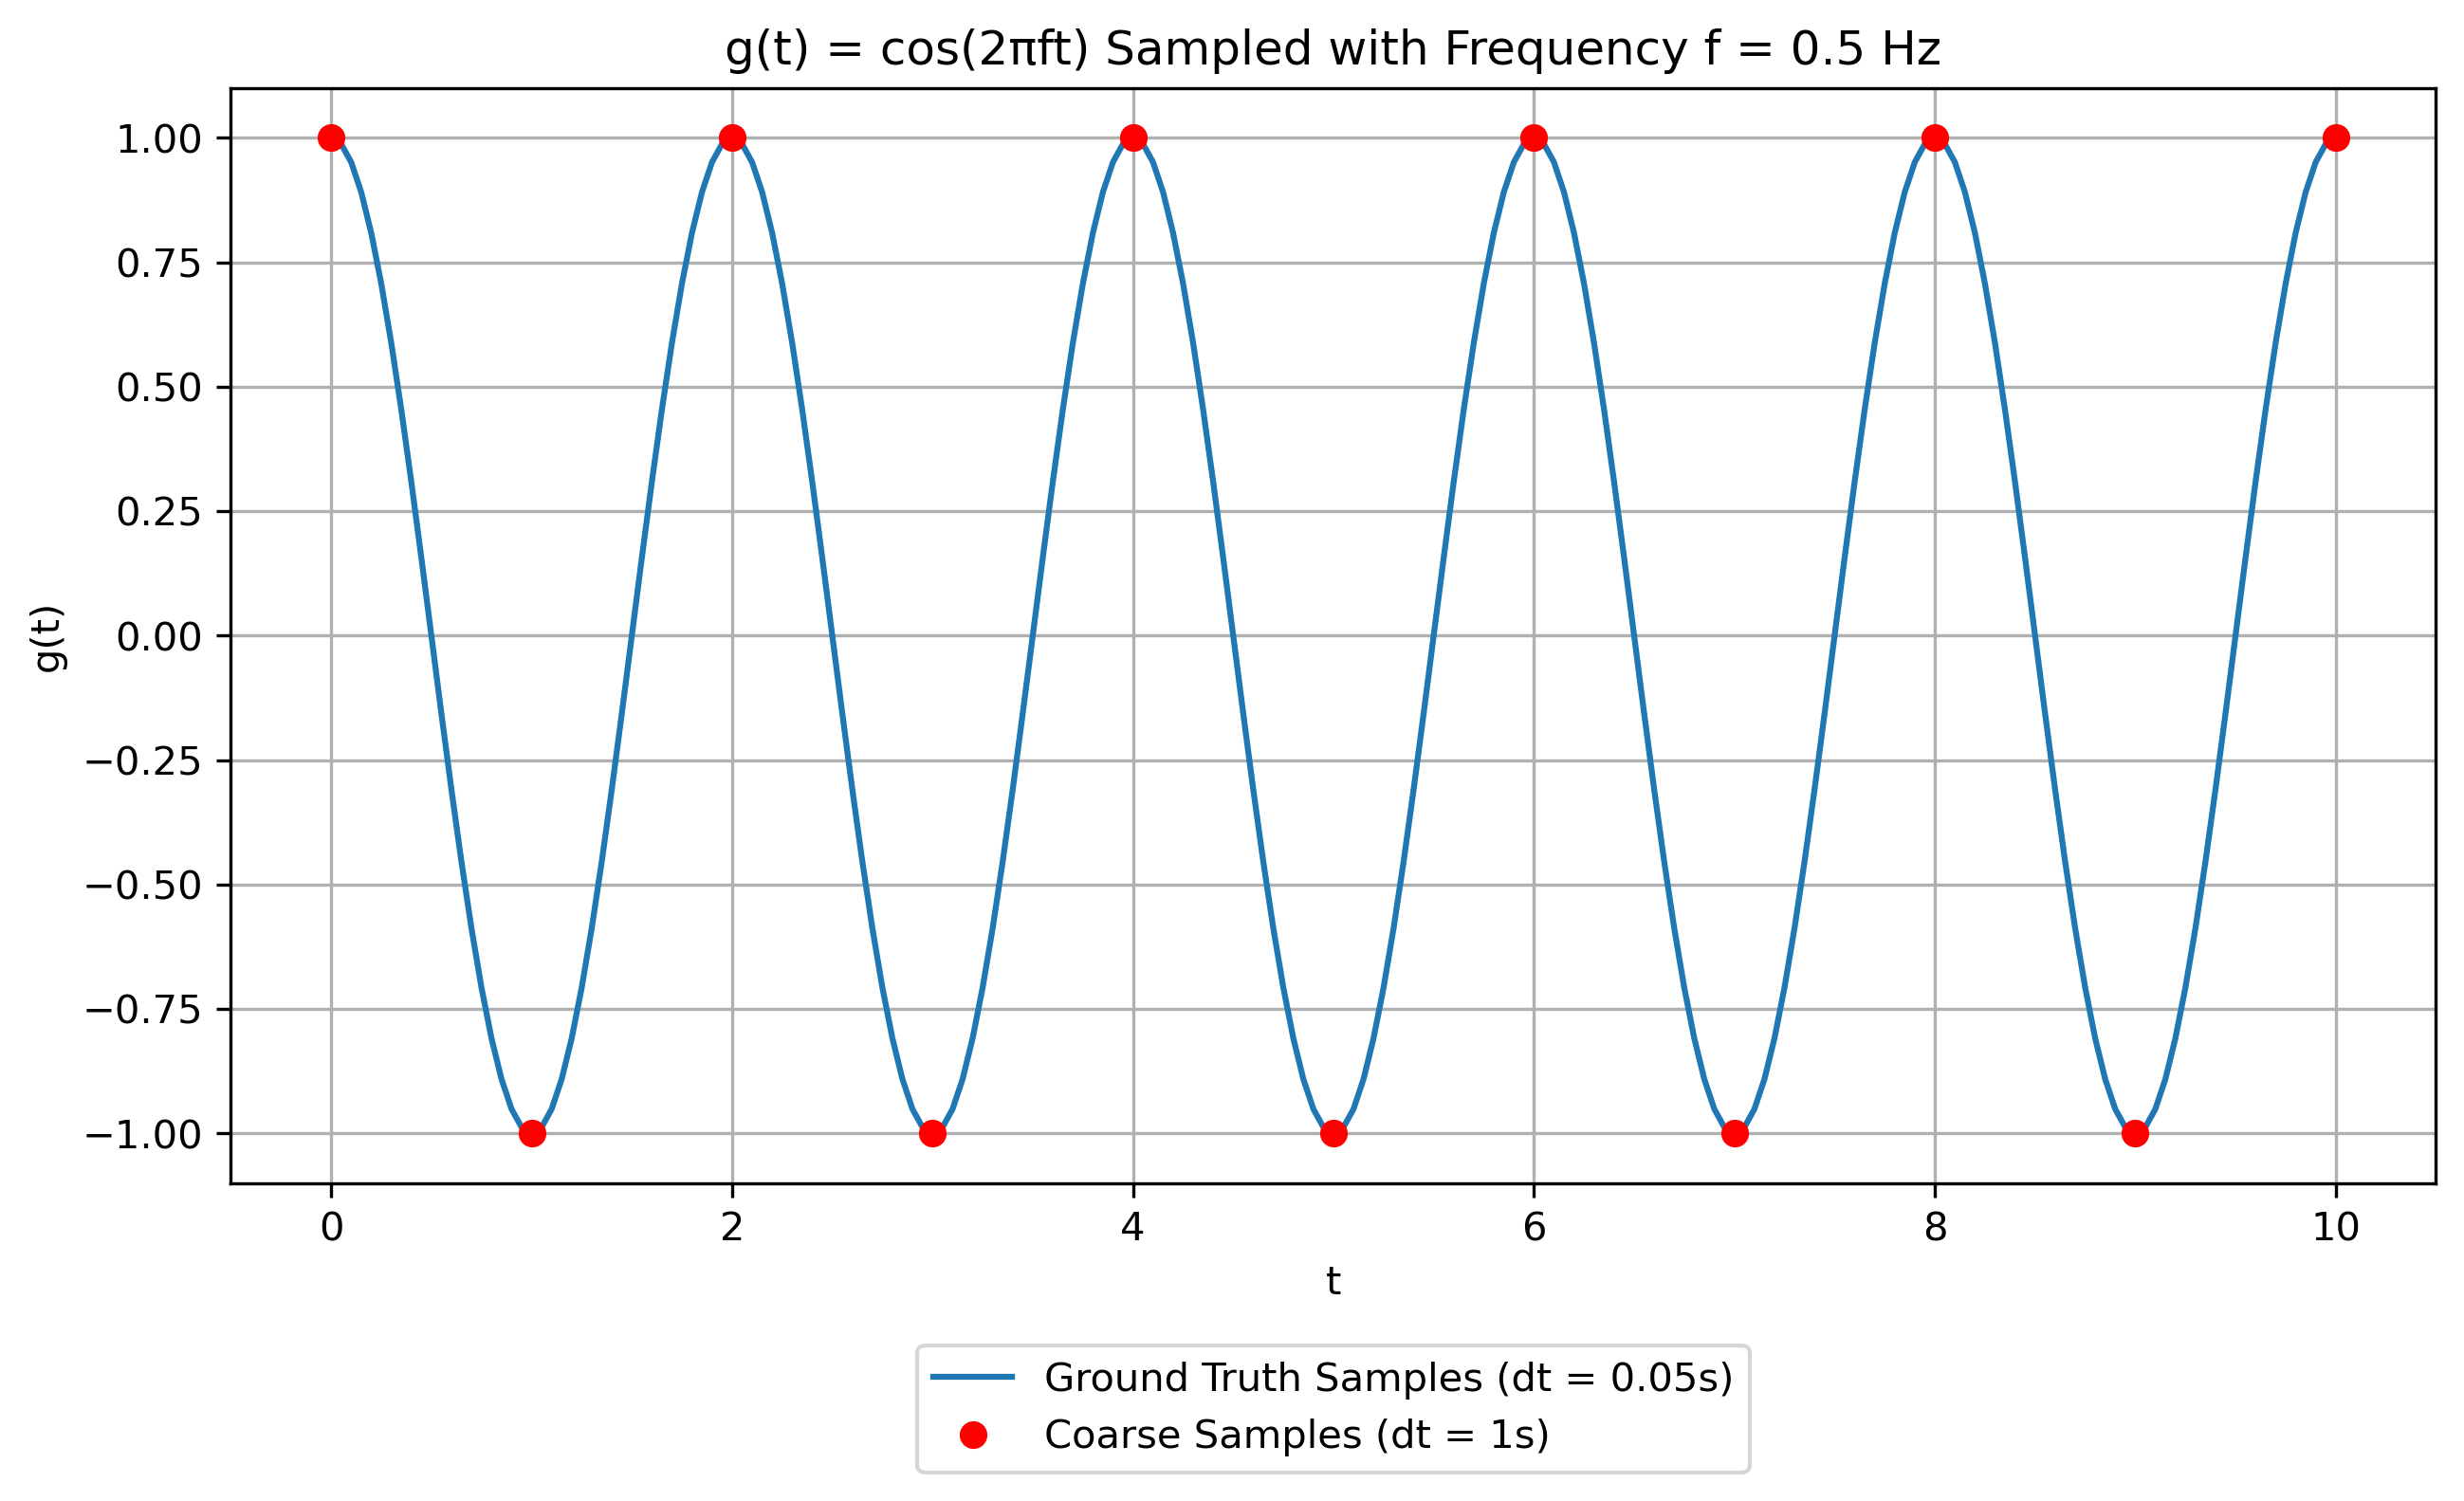

Average is 0.09090909090909091 for ground truth f = 0.5
Ground truth frequency = 0.5, Sampled/Apparent frequency = 0.5
Amplitude of sampled data for ground truth f = 0.5 is 1.0


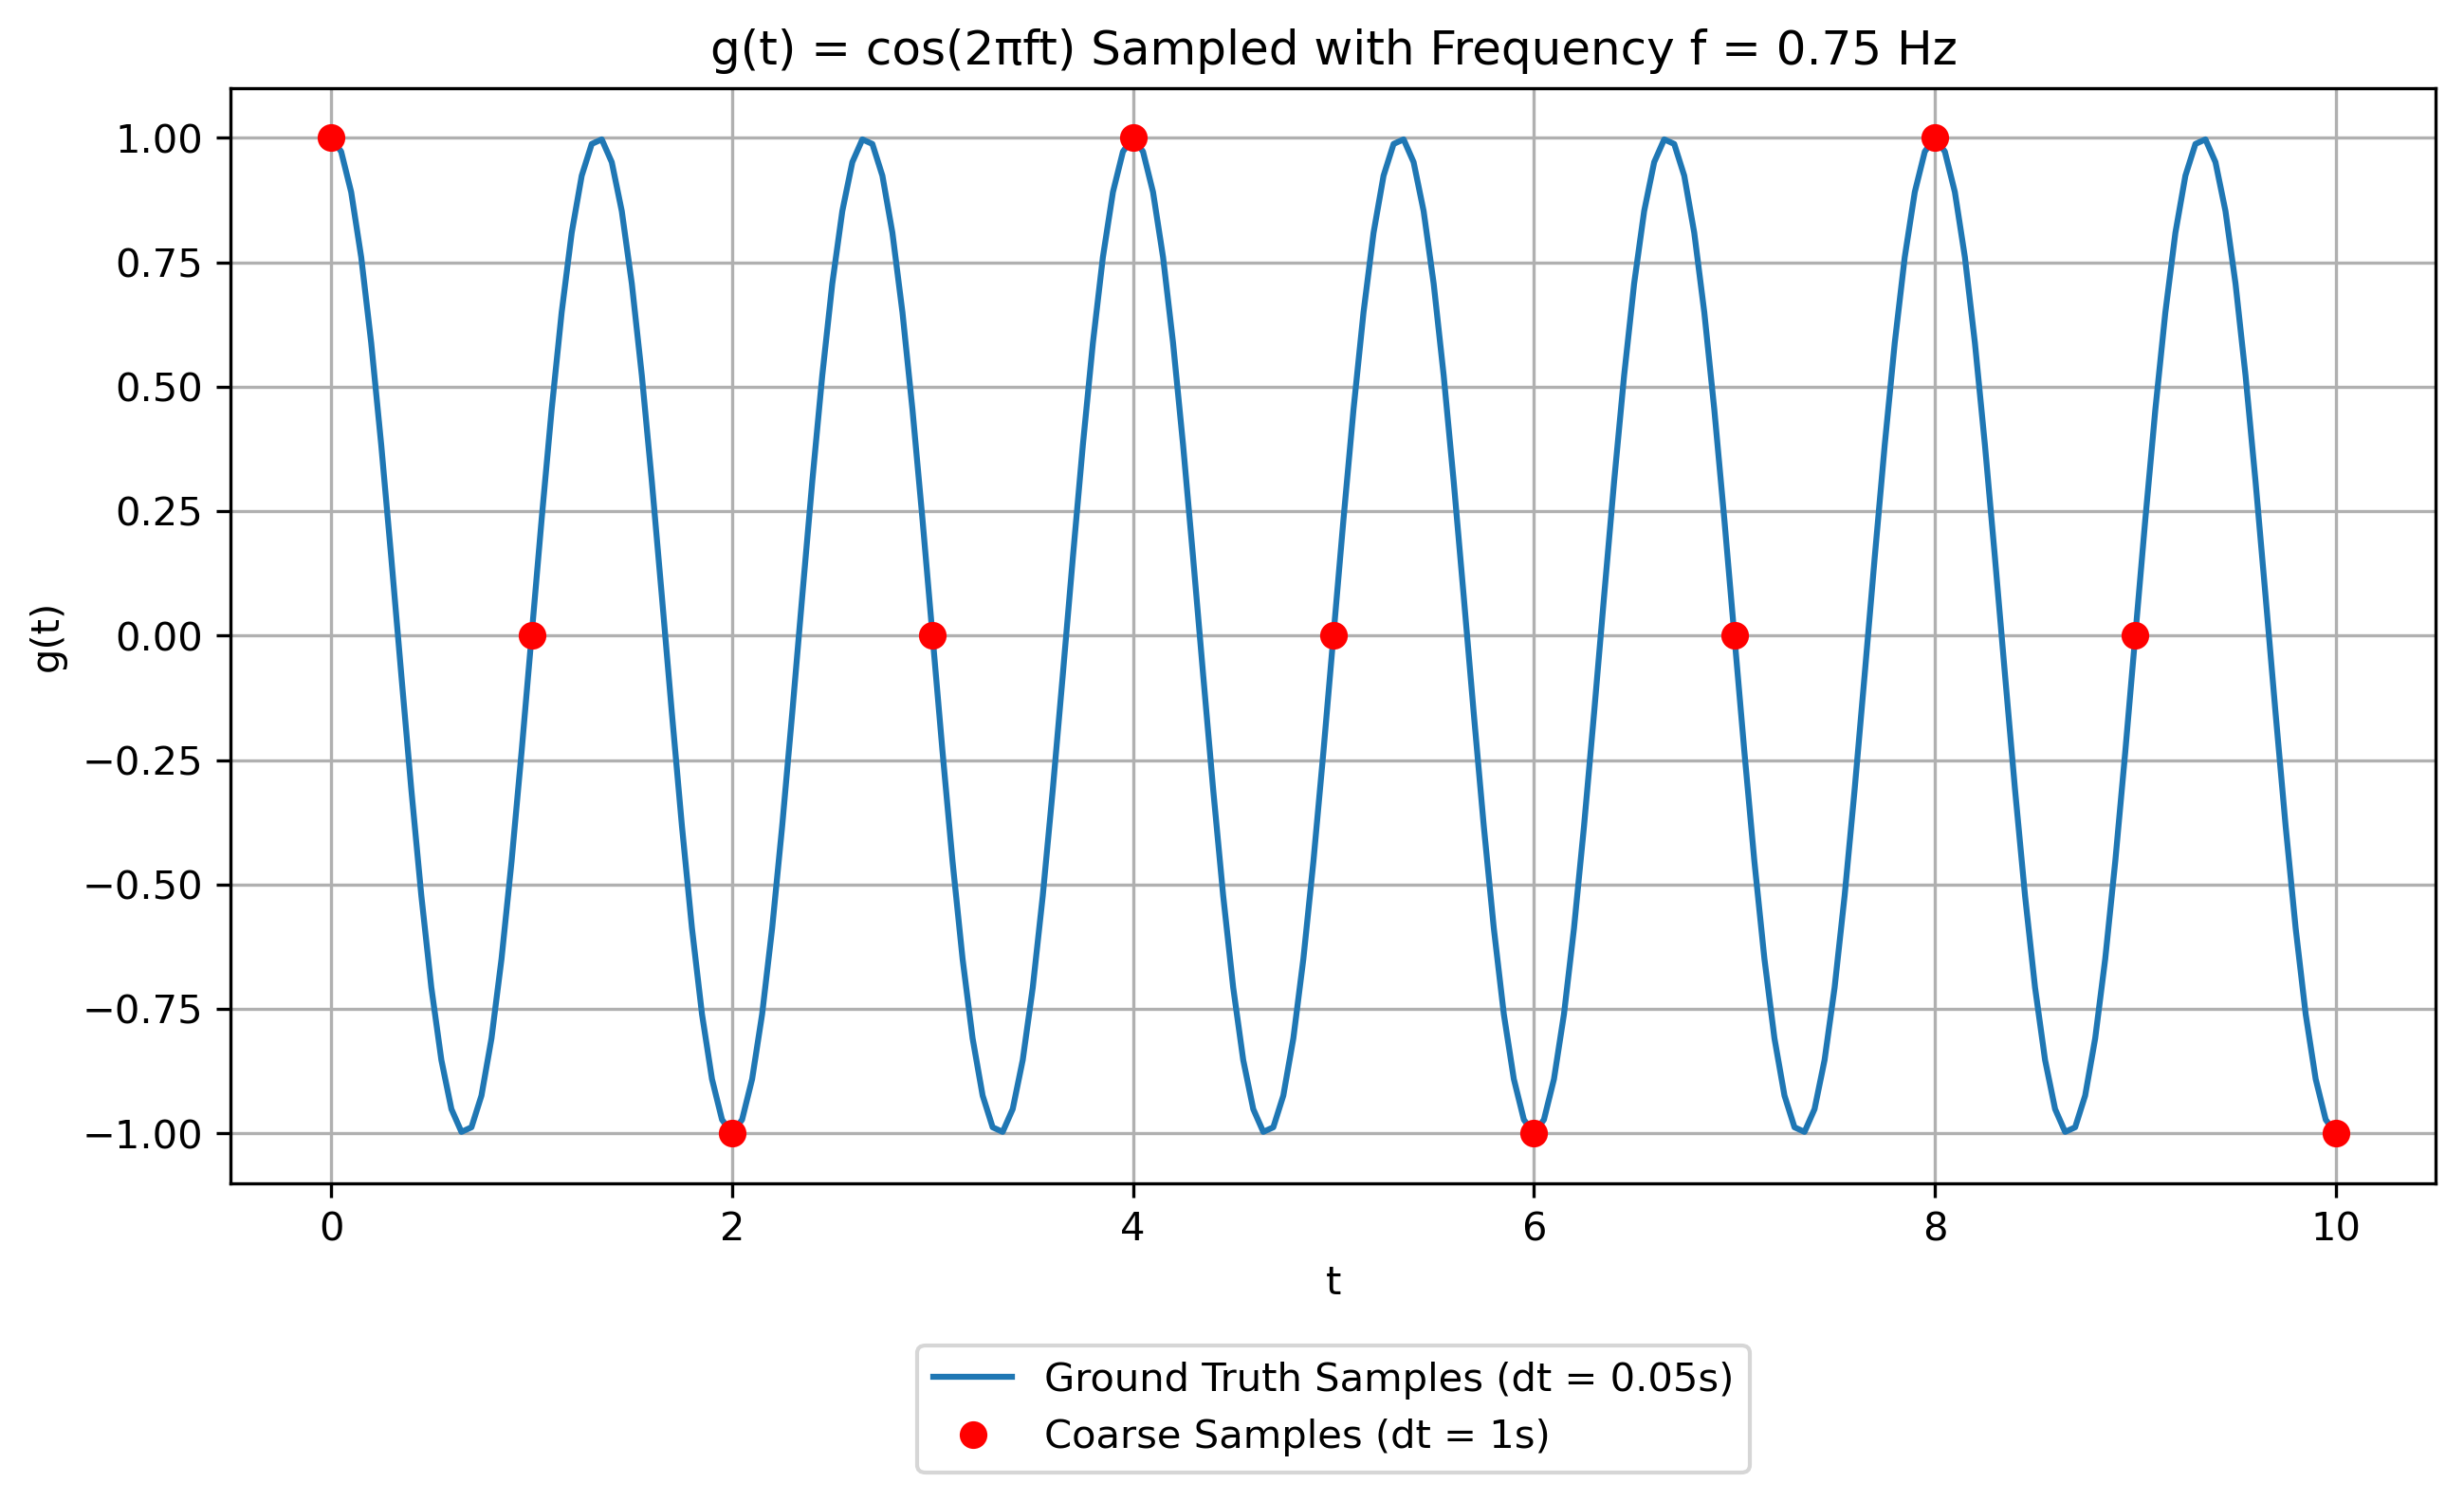

Average is -5.652044489000797e-16 for ground truth f = 0.75
Ground truth frequency = 0.75, Sampled/Apparent frequency = 0.25
Amplitude of sampled data for ground truth f = 0.75 is 1.0


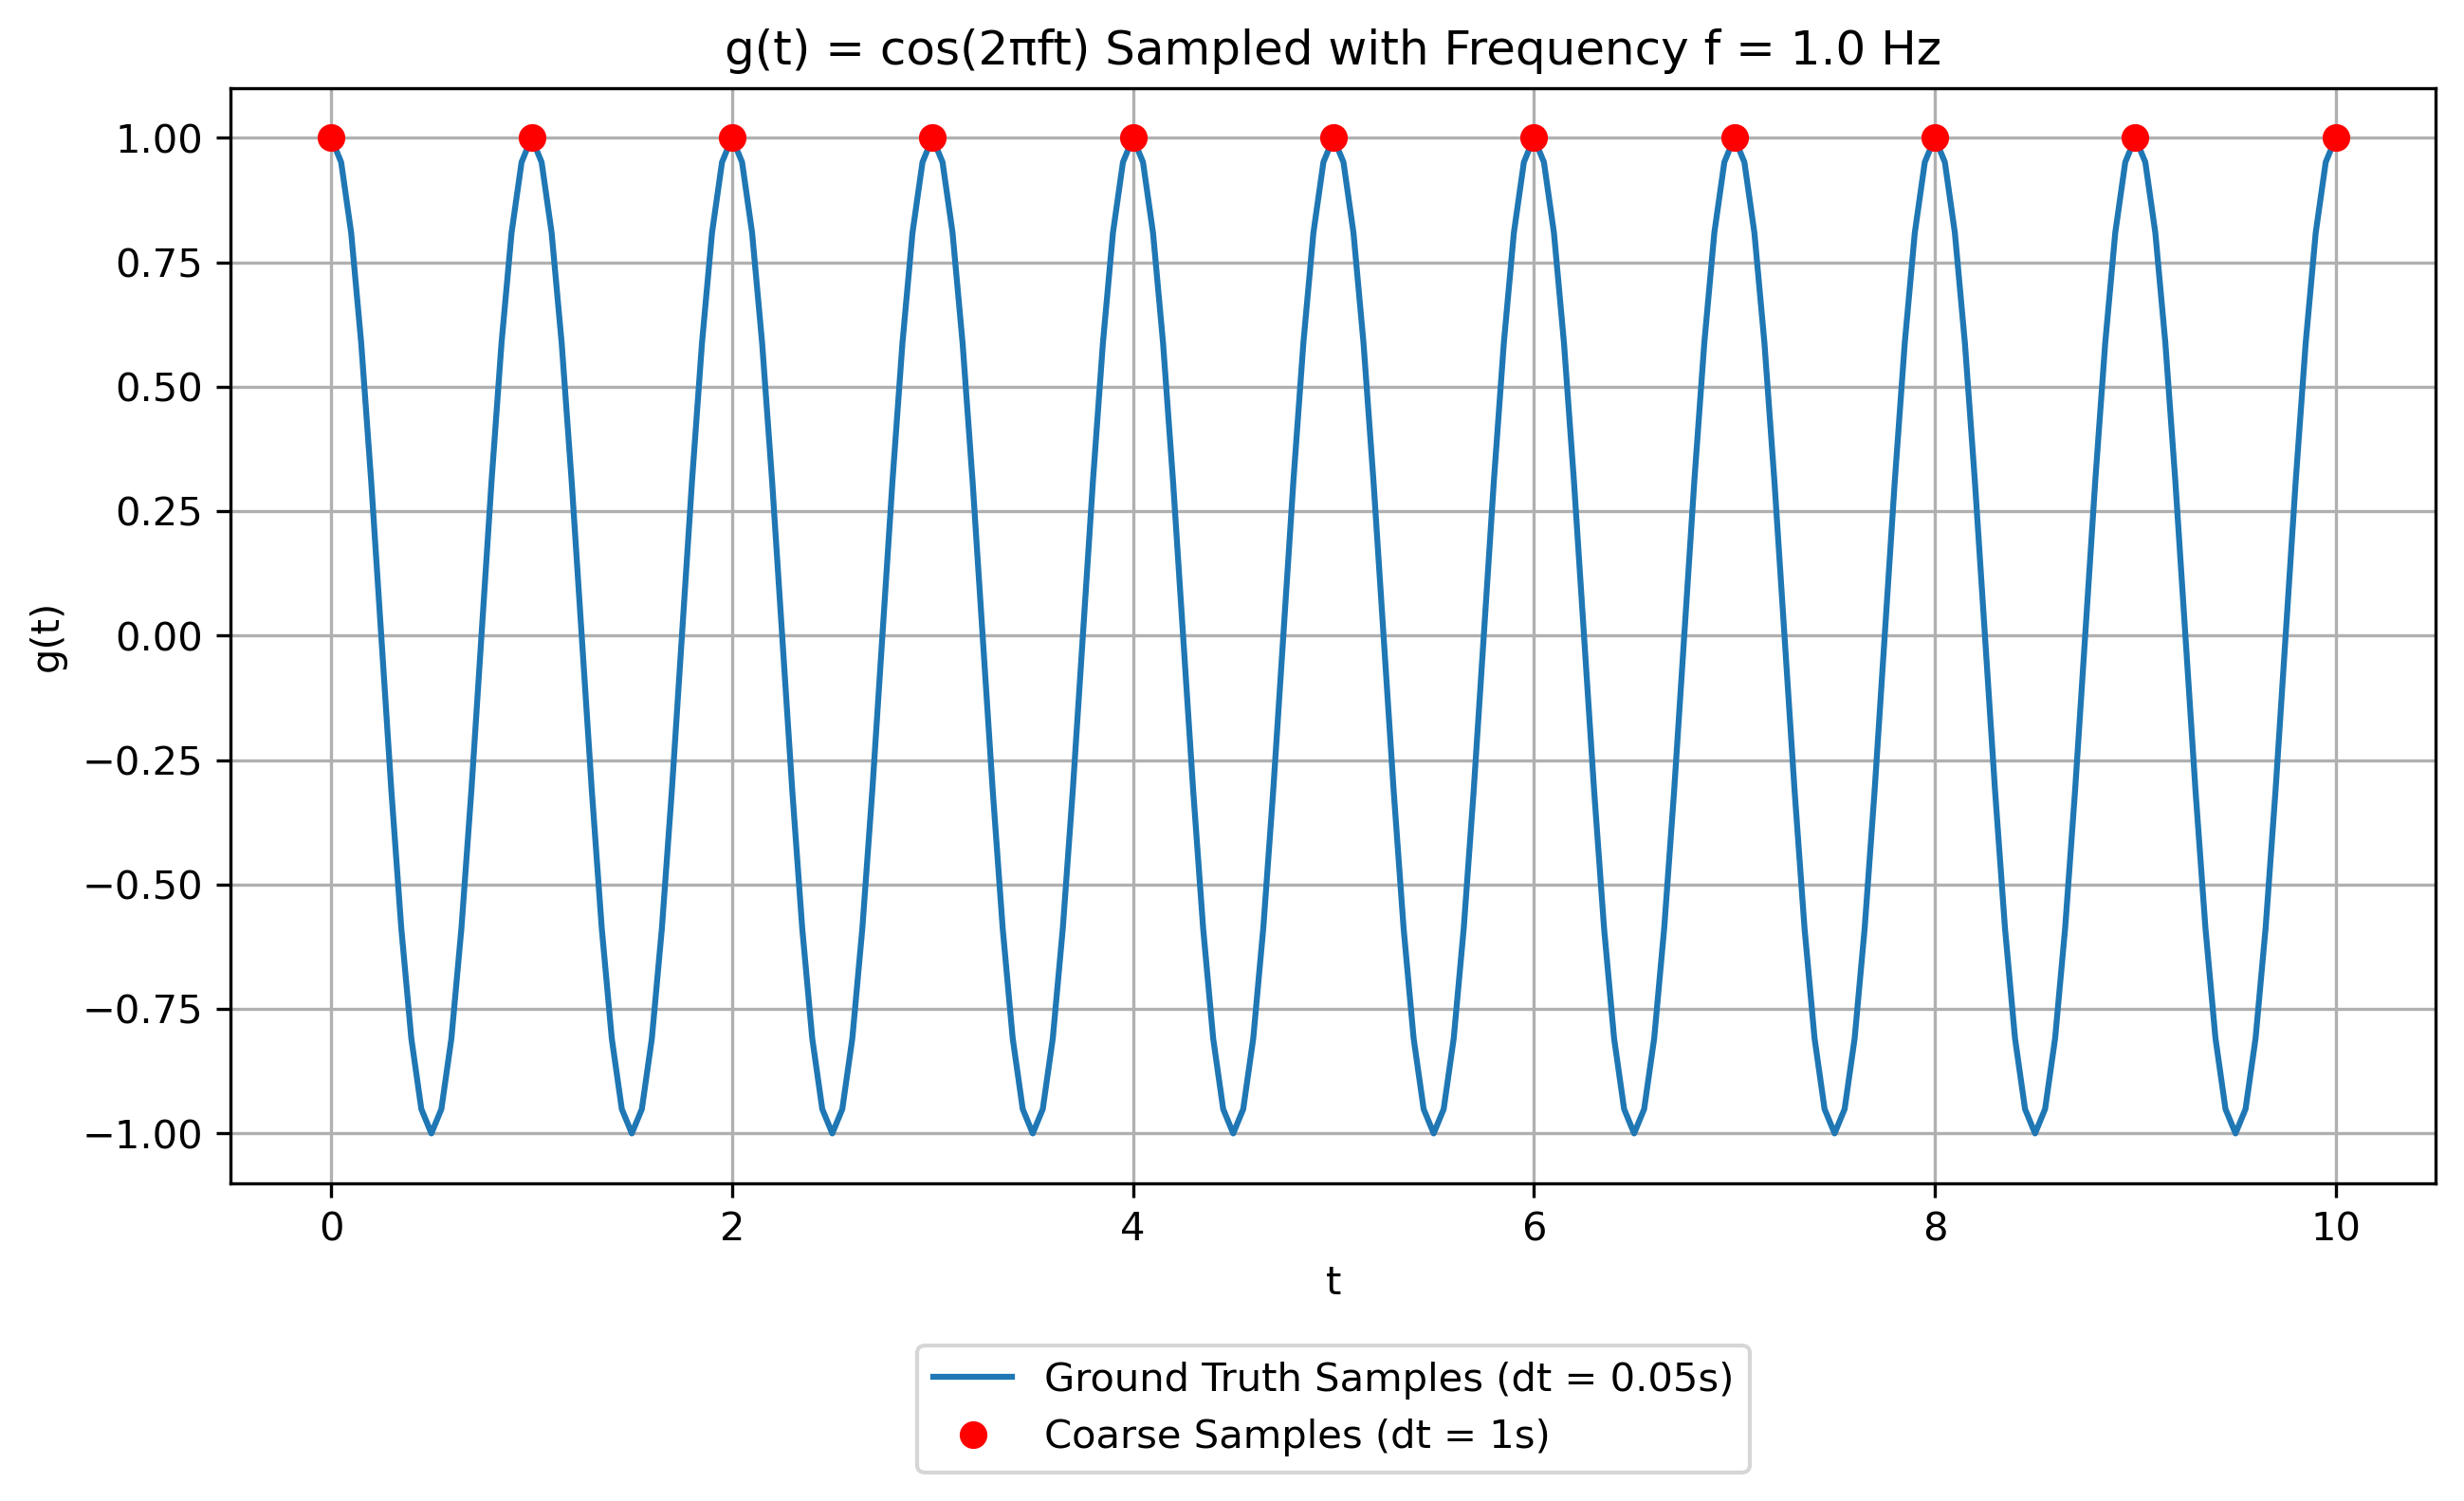

Average is 1.0 for ground truth f = 1.0
No periodicity detected for ground f = 1.0
Amplitude of sampled data for ground truth f = 1.0 is 0.0


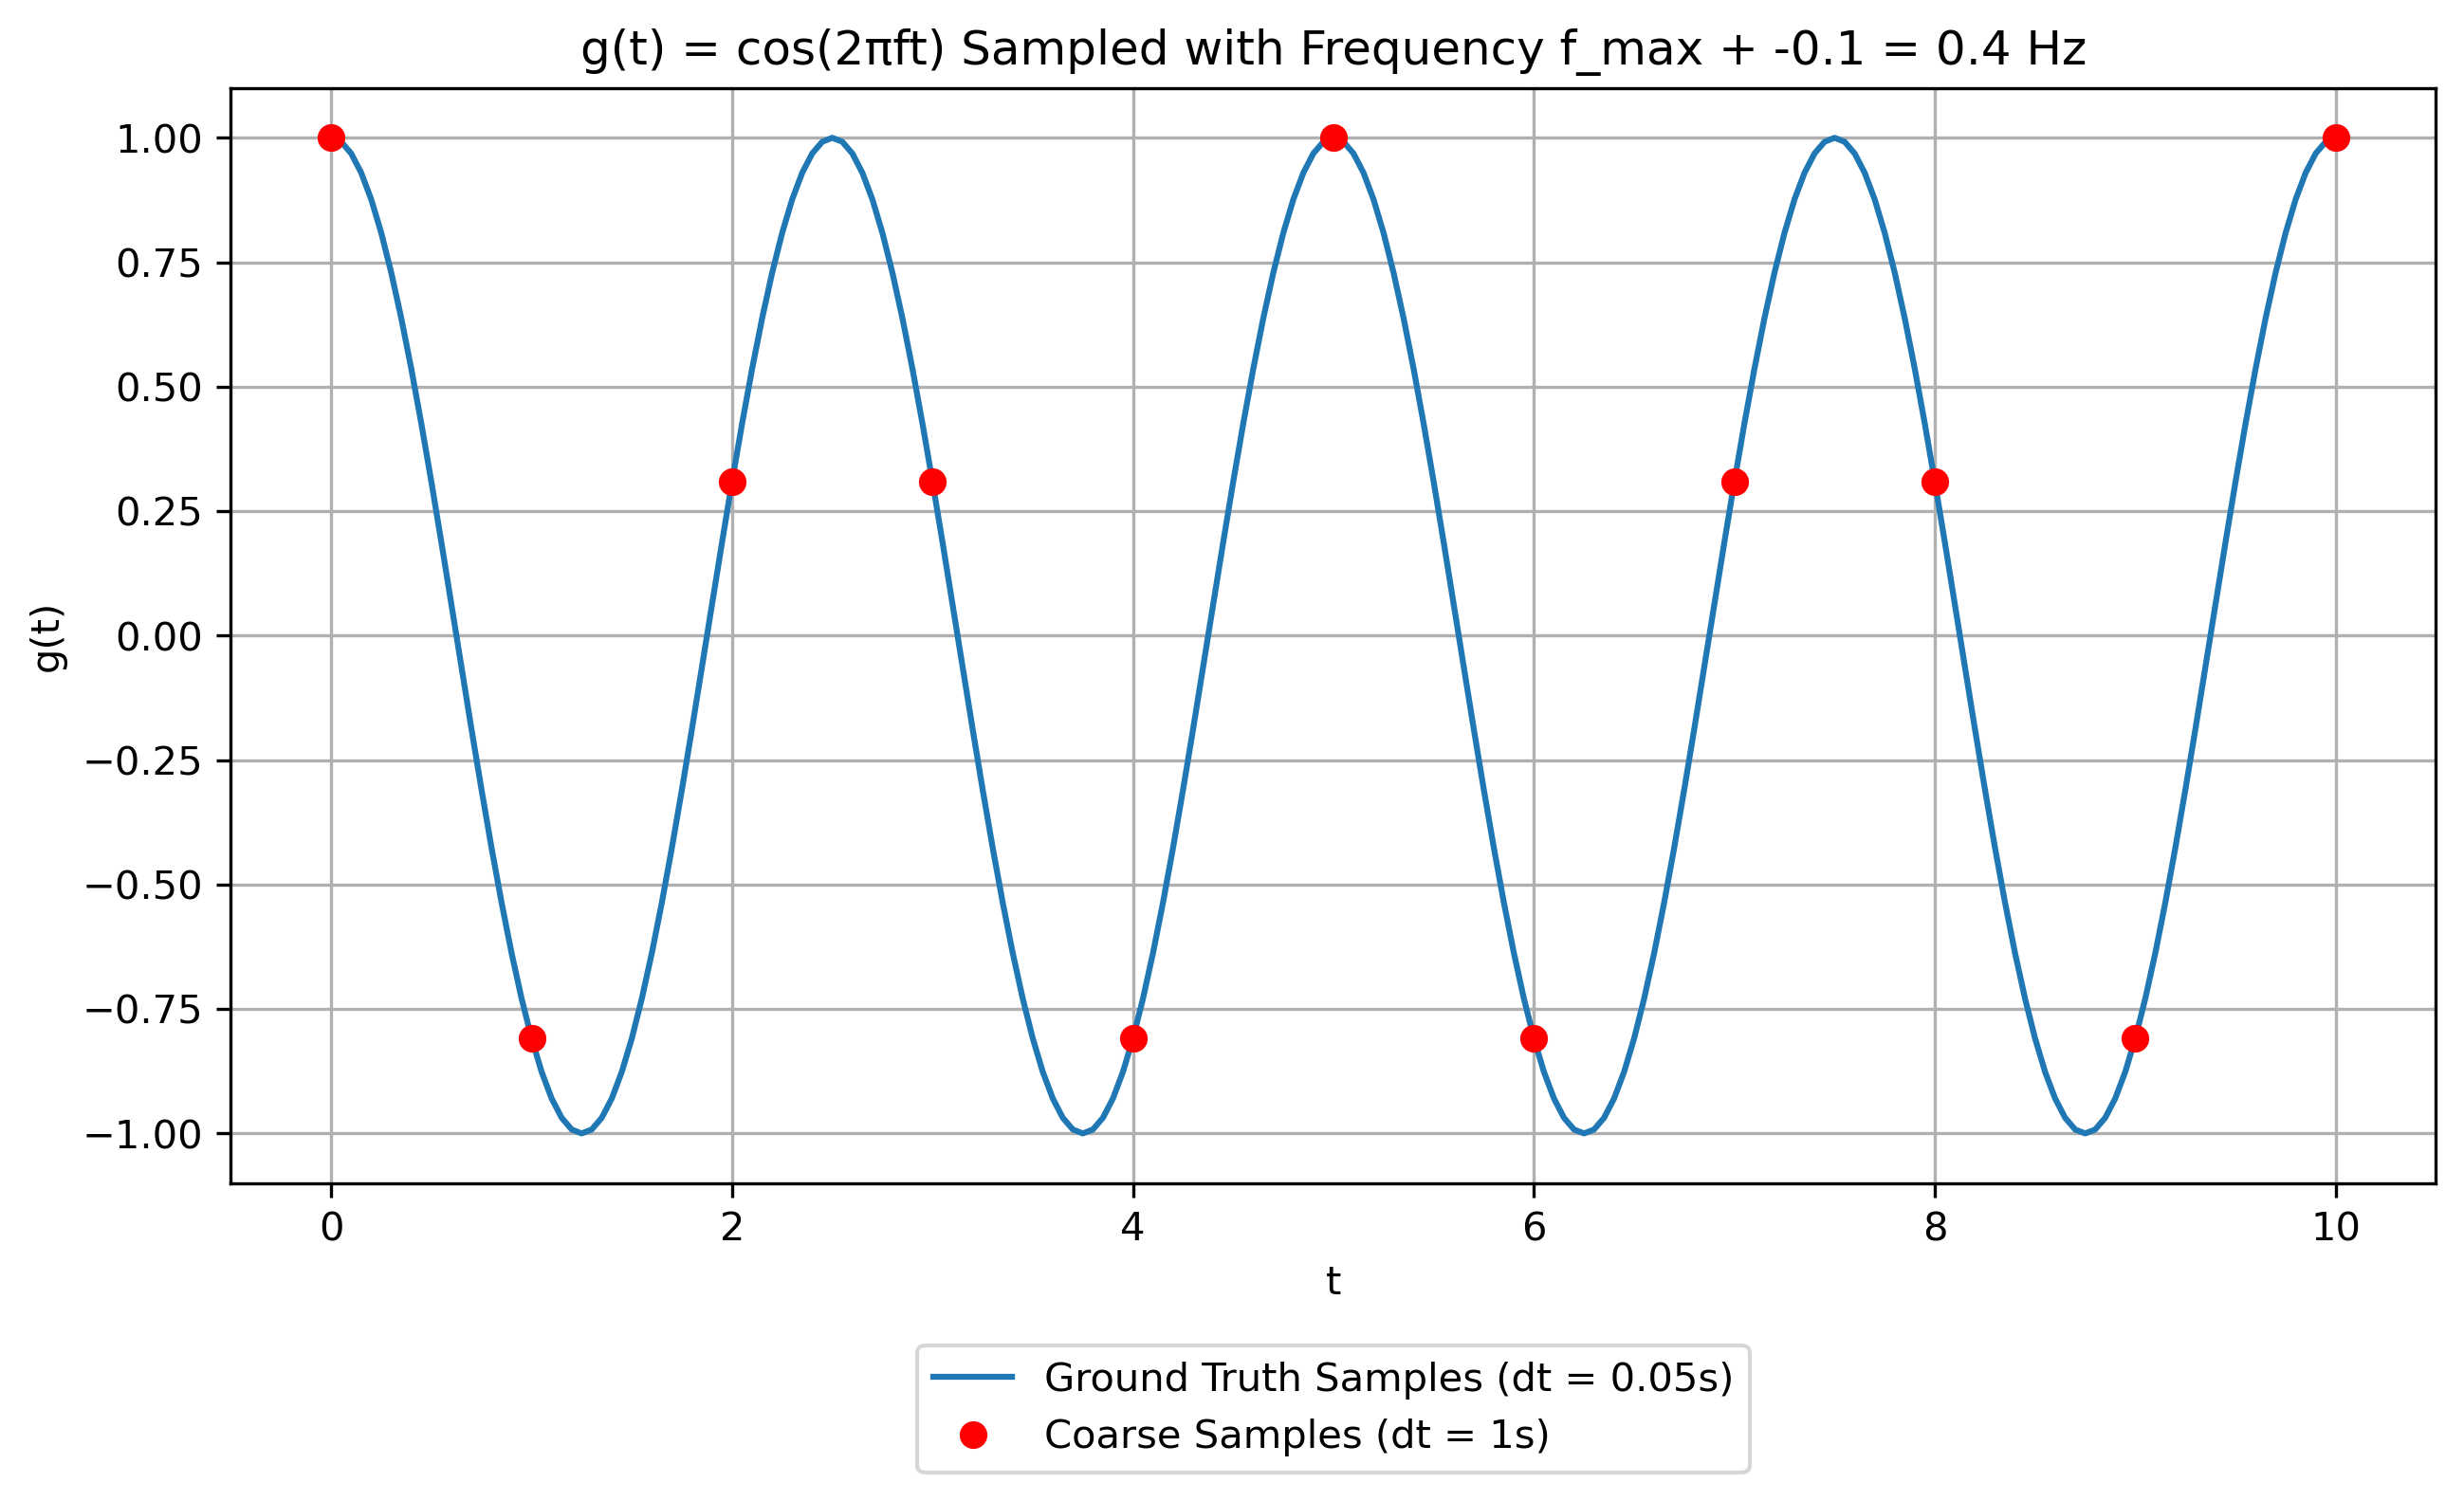

For f_max + -0.1 = 0.4, Average is 0.09090909090909088
Ground truth frequency = 0.4, Sampled/Apparent frequency = 0.2
Amplitude of sampled data for ground truth fmax + -0.1 = 0.4 is 0.904508497187474


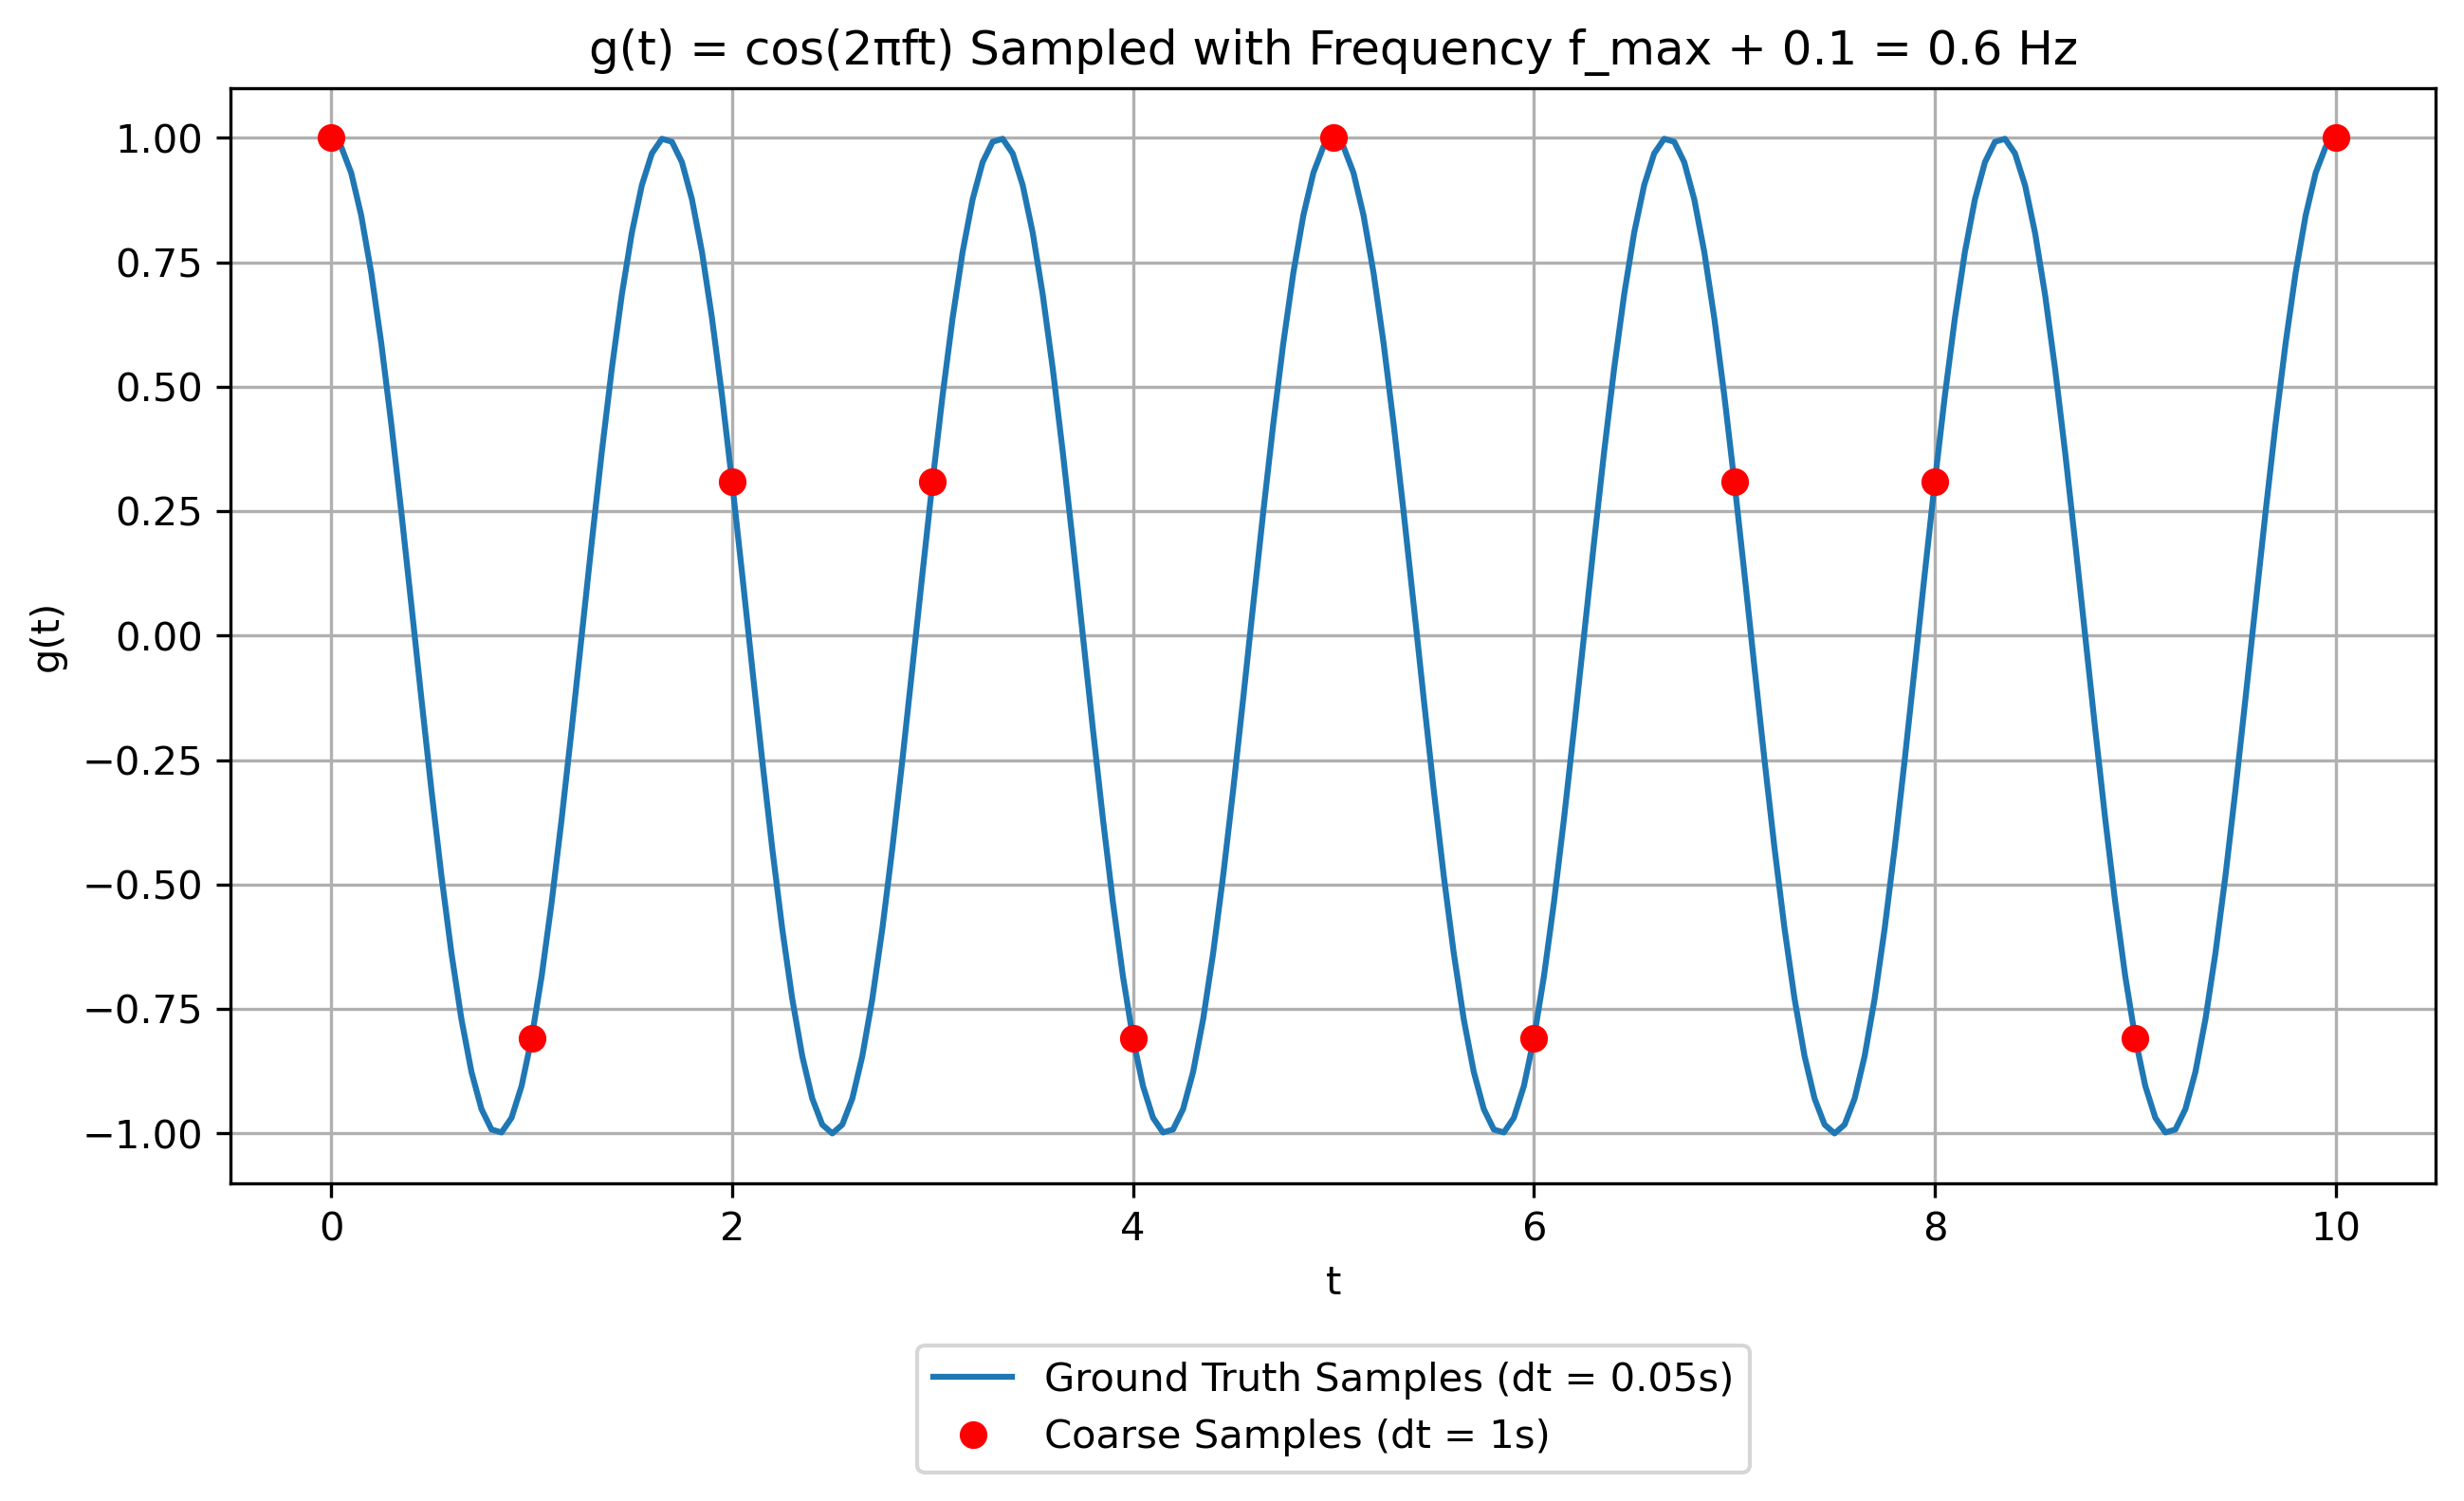

For f_max + 0.1 = 0.6, Average is 0.09090909090909095
Ground truth frequency = 0.6, Sampled/Apparent frequency = 0.2
Amplitude of sampled data for ground truth fmax + 0.1 = 0.6 is 0.904508497187474


In [12]:
# Question 3: Sampling Data

# Importing Libraries
import numpy as np 
import matplotlib.pyplot as plt 

plt.rcParams['figure.dpi'] = 300 # set higher resolution figures

# Initialise variables

dt = 1 # second
dt_ground = 0.05 # Much finer
t_1 = np.arange(0, 10+dt, dt)
t_2 = np.arange(0, 10+dt_ground, dt_ground)
frequencies = [0, 0.25, 0.5, 0.75, 1.0]

# Plot each coarsely sampled data for each frequency in one plot 

for f in frequencies: 
    
    # Part a) Generate a sample of data g(t) = cos(2πft)
    g_t_1 = np.cos(2 * np.pi * f * t_1) # coarse sampling
    g_t_2 = np.cos(2 * np.pi * f * t_2) # 'ground truth' sampling
    
    
    # Plot both on same plot 
    plt.figure(figsize=(10, 5))
    plt.plot(t_2, g_t_2, label = 'Ground Truth Samples (dt = 0.05s)')
    plt.plot(t_1, g_t_1, 'ro', label = 'Coarse Samples (dt = 1s)')
    plt.xlabel('t')
    plt.ylabel('g(t)')
    plt.title(f'g(t) = cos(2πft) Sampled with Frequency f = {f} Hz')
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13))
    plt.grid(True)
    plt.show()
    
    # Part b) calculate average value, frequency and amplitude of coarse data
    
    # Average
    
    average = np.average(g_t_1)
    
    print(f'Average is {average} for ground truth f = {f}')
    
    # Frequency - how long it takes to repeat inversed 
    
    T_1 = None
    for k in range(1, len(g_t_1)-1): 
        if abs(g_t_1[k] - g_t_1[0]) < 1e-6:
            # slope direction check
            if (g_t_1[1] - g_t_1[0]) * (g_t_1[k+1] - g_t_1[k]) > 0:
                T_1 = k * dt
                break
            
    if T_1 is None:
        print(f"No periodicity detected for ground f = {f}")
    else:
        freq = 1 / T_1

        # compare them
        print(f'Ground truth frequency = {f}, Sampled/Apparent frequency = {freq}')
    
    # Amplitude
    
    amplitude = (max(g_t_1) - min(g_t_1))/2
    
    print(f'Amplitude of sampled data for ground truth f = {f} is {amplitude}')
    
    
# Part c): Around estimated maximum, generate new samples

# Estimated maximum: 
f_max = 0.5 

# Generate new samples:
for i in [-0.1, 0.1]:
    
    g_t_fmax = np.cos(2 * np.pi * (f_max + i) * t_1)
    g_ground_fmax = np.cos(2 * np.pi * (f_max + i) * t_2)
    
    # Plot both on same plot 
    plt.figure(figsize=(10, 5))
    plt.plot(t_2, g_ground_fmax, label = 'Ground Truth Samples (dt = 0.05s)')
    plt.plot(t_1, g_t_fmax, 'ro', label = 'Coarse Samples (dt = 1s)')
    plt.xlabel('t')
    plt.ylabel('g(t)')
    plt.title(f'g(t) = cos(2πft) Sampled with Frequency f_max + {i} = {f_max + i} Hz')
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13))
    plt.grid(True)
    plt.show()


    # Calculate average value frequency and amplitude of coarse data
    
    # Average

    avg_fmax = np.average(g_t_fmax)

    print(f'For f_max + {i} = {f_max + i}, Average is {avg_fmax}')
    
    T_fmax = None
    # Frequency 
    for k in range(1, len(g_t_fmax)-1): 
        if abs(g_t_fmax[k] - g_t_fmax[0]) < 1e-6:
            # slope direction check
            if (g_t_fmax[1] - g_t_fmax[0]) * (g_t_fmax[k+1] - g_t_fmax[k]) > 0:
                T_fmax = k * dt
                break

    if T_fmax is None:
        print(f"No periodicity detected for ground f = {f_max + i}")
    else:
        freq_fmax = 1 / T_fmax

        # compare them
        print(f'Ground truth frequency = {f_max + i}, Sampled/Apparent frequency = {freq_fmax}')

    # Amplitude

    amplitude_fmax = (max(g_t_fmax) - min(g_t_fmax))/2

    print(f'Amplitude of sampled data for ground truth fmax + {i} = {f_max + i} is {amplitude_fmax}')